# 02 · Returns, correlation and distance

For each share *i* the daily log-return is

$$ r_i(t) = \ln P_i(t) - \ln P_i(t-1) $$

The Pearson correlation between two shares is

$$ \rho_{ij} = \frac{\langle r_i r_j \rangle - \langle r_i \rangle \langle r_j \rangle}
{\sqrt{\left(\langle r_i^2 \rangle - \langle r_i \rangle^2\right)\left(\langle r_j^2 \rangle - \langle r_j \rangle^2\right)}} $$

Correlation is not a distance, so it is mapped to the Mantegna (1999) metric

$$ d_{ij} = \sqrt{2\,(1 - \rho_{ij})}, \qquad d \in [0, 2]. $$

The distance is 0 for perfectly co-moving shares, $\sqrt 2$ for uncorrelated ones and
2 for perfectly anti-correlated ones. Unlike $1-\rho$, it satisfies the triangle
inequality, so building a tree from it is well defined.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
from IPython.display import Image, display

from moex_network import config, correlation, data, metrics, mst, plotting

plotting.use_style()
pd.set_option("display.precision", 3)

In [2]:
prices = data.load_prices(config.CLEAN_PRICES)
returns = correlation.log_returns(prices)
corr = correlation.correlation_matrix(returns)
dist = correlation.correlation_to_distance(corr)

corr.to_csv(config.CORRELATION_MATRIX)
dist.to_csv(config.DISTANCE_MATRIX)
print(f"{returns.shape[0]} daily returns x {returns.shape[1]} shares → "
      f"{len(corr) * (len(corr) - 1) // 2} distinct pairs")

866 daily returns x 44 shares → 946 distinct pairs


In [3]:
pairs = correlation.pairs(corr)
pairs["rho"].describe()

count    946.000
mean       0.385
std        0.110
min        0.106
25%        0.306
50%        0.389
75%        0.464
max        0.765
Name: rho, dtype: float64

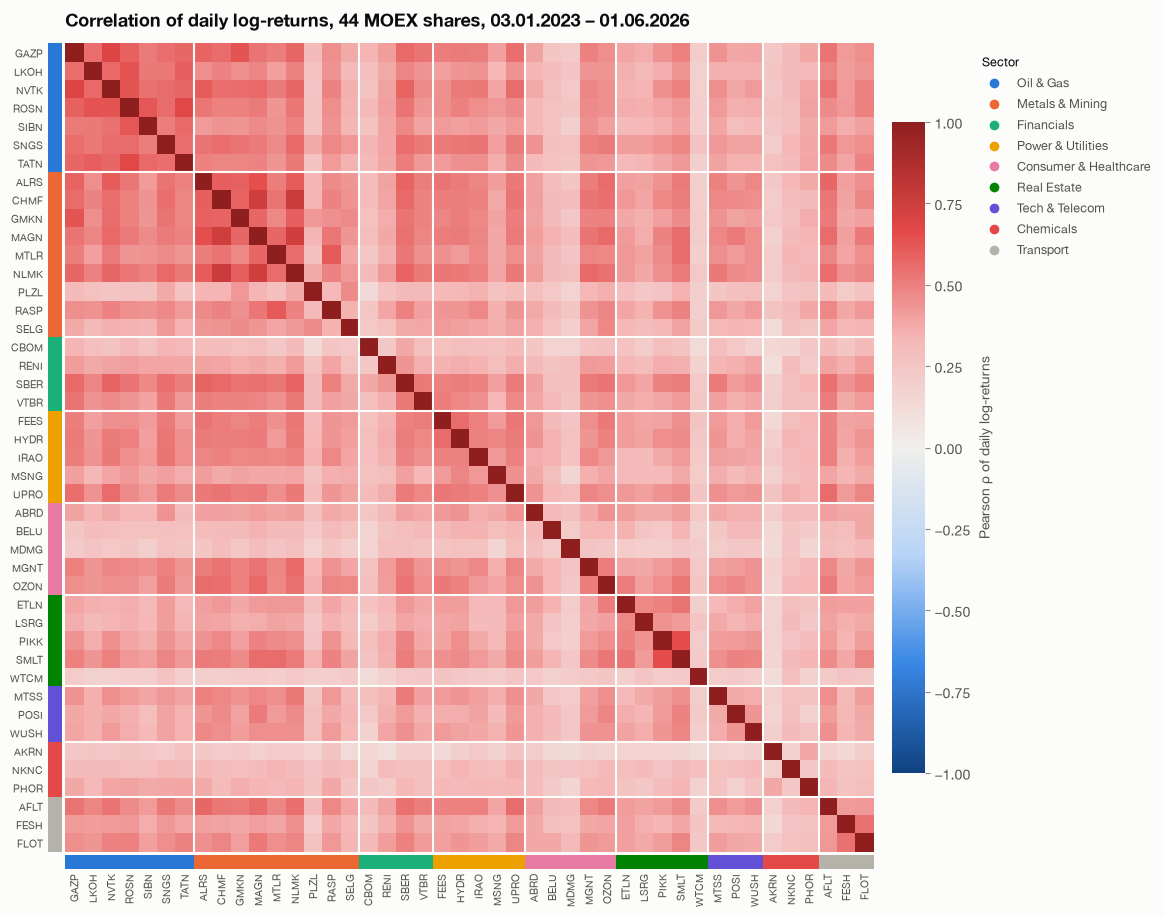

In [4]:
period = f"{prices.index[0]:%d.%m.%Y} – {prices.index[-1]:%d.%m.%Y}"
plotting.plot_correlation_heatmap(
    corr, f"Correlation of daily log-returns, 44 MOEX shares, {period}",
    path=config.FIGURES_DIR / "correlation_heatmap.png");

Grouping the tickers by sector makes the block structure visible. Oil & gas, metals and
power utilities form clear blocks, and there is a broad positive "market mode": almost
every pair is positively correlated.

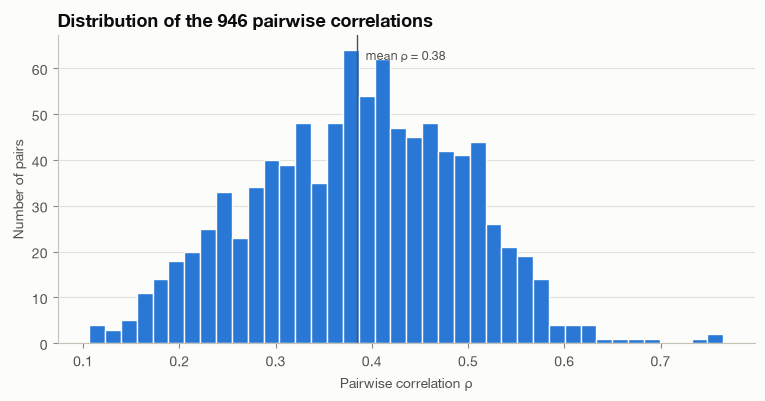

In [5]:
plotting.plot_correlation_distribution(
    pairs, "Distribution of the 946 pairwise correlations",
    path=config.FIGURES_DIR / "correlation_distribution.png");

## Strongest and weakest links

In [6]:
pairs["sector_a"] = pairs["a"].map(config.SECTOR_OF)
pairs["sector_b"] = pairs["b"].map(config.SECTOR_OF)
pairs.sort_values("rho", ascending=False).head(10)

,a,b,rho,sector_a,sector_b
481,CHMF,NLMK,0.765,Metals & Mining,Metals & Mining
482,CHMF,MAGN,0.749,Metals & Mining,Metals & Mining
511,NLMK,MAGN,0.740,Metals & Mining,Metals & Mining
168,GAZP,NVTK,0.691,Oil & Gas,Oil & Gas
244,ROSN,TATN,0.677,Oil & Gas,Oil & Gas
918,PIKK,SMLT,0.651,Real Estate,Real Estate
541,MAGN,ALRS,0.644,Metals & Mining,Metals & Mining
205,LKOH,ROSN,0.633,Oil & Gas,Oil & Gas
243,ROSN,NVTK,0.632,Oil & Gas,Oil & Gas
173,GAZP,GMKN,0.629,Oil & Gas,Metals & Mining


In [7]:
pairs.sort_values("rho").head(10)

,a,b,rho,sector_a,sector_b
152,RENI,AKRN,0.106,Financials,Chemicals
827,WTCM,AKRN,0.109,Real Estate,Chemicals
632,SELG,AKRN,0.119,Metals & Mining,Chemicals
110,CBOM,WTCM,0.120,Financials,Real Estate
867,AKRN,MDMG,0.128,Chemicals,Consumer & Healthcare
858,AKRN,FEES,0.135,Chemicals,Power & Utilities
98,CBOM,PLZL,0.135,Financials,Metals & Mining
112,CBOM,AKRN,0.144,Financials,Chemicals
742,BELU,AKRN,0.146,Consumer & Healthcare,Chemicals
701,FESH,AKRN,0.147,Transport,Chemicals


## Sector cohesion

The table compares the average correlation *inside* each sector with that sector's average
correlation with the rest of the market. A large gap means the sector trades as a group.

In [8]:
cohesion = metrics.sector_cohesion(corr)
cohesion["gap"] = cohesion["mean_rho_within"] - cohesion["mean_rho_outside"]
cohesion

,n,mean_rho_within,mean_rho_outside,gap
sector,,,,
Oil & Gas,7,0.576,0.407,0.169
Metals & Mining,9,0.498,0.403,0.095
Power & Utilities,5,0.485,0.403,0.082
Transport,3,0.462,0.400,0.063
Real Estate,5,0.389,0.345,0.044
Tech & Telecom,3,0.387,0.373,0.014
Financials,4,0.368,0.367,0.001
Consumer & Healthcare,5,0.330,0.351,-0.022
Chemicals,3,0.265,0.264,0.001
